# State Preparation — Cluster States (CUDA-Q)
## 4-Qubit Linear Cluster State

**Chapter / concept:** State Preparation — Graph / Cluster States (Measurement-Based Quantum Computing building block)

**Circuit implemented:** 4-qubit linear-chain cluster state on graph `0 — 1 — 2 — 3`
(edges: (0,1), (1,2), (2,3)) — matches the Qiskit notebook exactly.

### Global SETUP (must match the Qiskit notebook exactly)
- N_QUBITS = 4
- Gate sequence: `H` on every qubit (q0,q1,q2,q3), then `CZ(0,1)`, `CZ(1,2)`, `CZ(2,3)` (in that order)
- QUBIT ORDERING CONTRACT: qubit 0 = **rightmost** bit in every FINAL printed bitstring
- SHOTS = 10000, SEED = 42
- GLOBAL PHASE CONVENTION: the first amplitude with `abs(amp) > 1e-9`, in ascending
  bitstring order (after the ordering fix below), is rotated to be real and positive
- Basis ordering for all matrices: `{|00..0>, |00..1>, ..., |11..1>}` ascending binary order

### Theory recap
Same as the Qiskit notebook:
$$|\psi_G\rangle = \prod_{(i,j)\in E} CZ_{i,j} \; H^{\otimes n} |0\rangle^{\otimes n}$$
Every computational basis amplitude has magnitude $1/4$, sign
$(-1)^{q_0 q_1 + q_1 q_2 + q_2 q_3}$, and the measurement distribution is **exactly uniform**:
every one of the 16 outcomes has probability $1/16 = 0.0625$.

### ⚠️ ORDERING-CONVENTION WARNING (read before running)
**CUDA-Q's `get_state()` and `sample()` index qubit 0 as the most-significant (LEFTMOST) bit**
— the opposite of Qiskit. Every statevector amplitude index and every sampled bitstring
produced in this notebook is **explicitly reversed** in its own dedicated cell below so that
this notebook's final printed dictionaries use "qubit 0 = rightmost", matching the Qiskit
notebook. Do not compare raw CUDA-Q output to Qiskit output without that reversal.

**Run all cells top to bottom.**

In [2]:
# Install cell
# Exact package name: "cudaq" (NVIDIA CUDA-Q Python API). Platform caveat: cudaq wheels
# target Linux x86_64/aarch64; it runs in CPU simulation mode with no GPU present, which is
# all that's needed for this small 4-qubit state-vector simulation.
%pip install -q cudaq

In [3]:
# Imports + constants
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import cudaq

TOPIC_SLUG = "cluster_state_4q_linear"
N_QUBITS = 4
SHOTS = 10000
SEED = 42
EDGES = [(0, 1), (1, 2), (2, 3)]   # linear cluster-state graph, identical to the Qiskit notebook

cudaq.set_random_seed(SEED)

print("N_QUBITS:", N_QUBITS)
print("SHOTS:", SHOTS)
print("SEED:", SEED)
print("EDGES:", EDGES)

N_QUBITS: 4
SHOTS: 10000
SEED: 42
EDGES: [(0, 1), (1, 2), (2, 3)]


In [4]:
# Build the kernel gate-by-gate
@cudaq.kernel
def cluster_state_kernel():
    qubits = cudaq.qvector(N_QUBITS)

    # Step 1: put every qubit into |+> = H|0>, the standard cluster-state starting layer
    h(qubits[0])  # qubit 0 -> equal superposition |0>+|1>
    h(qubits[1])  # qubit 1 -> equal superposition |0>+|1>
    h(qubits[2])  # qubit 2 -> equal superposition |0>+|1>
    h(qubits[3])  # qubit 3 -> equal superposition |0>+|1>

    # Step 2: entangle neighboring qubits along the graph edges with controlled-Z.
    # z.ctrl(control, target) flips the sign of the amplitude wherever BOTH qubits are |1>
    # (CZ is symmetric in control/target, so the labeling doesn't change the resulting state).
    z.ctrl(qubits[0], qubits[1])  # edge (0,1)
    z.ctrl(qubits[1], qubits[2])  # edge (1,2)
    z.ctrl(qubits[2], qubits[3])  # edge (2,3)

print("Kernel 'cluster_state_kernel' defined.")

Kernel 'cluster_state_kernel' defined.


     ╭───╮               
q0 : ┤ h ├──●────────────
     ├───┤╭─┴─╮          
q1 : ┤ h ├┤ z ├──●───────
     ├───┤╰───╯╭─┴─╮     
q2 : ┤ h ├─────┤ z ├──●──
     ├───┤     ╰───╯╭─┴─╮
q3 : ┤ h ├──────────┤ z ├
     ╰───╯          ╰───╯



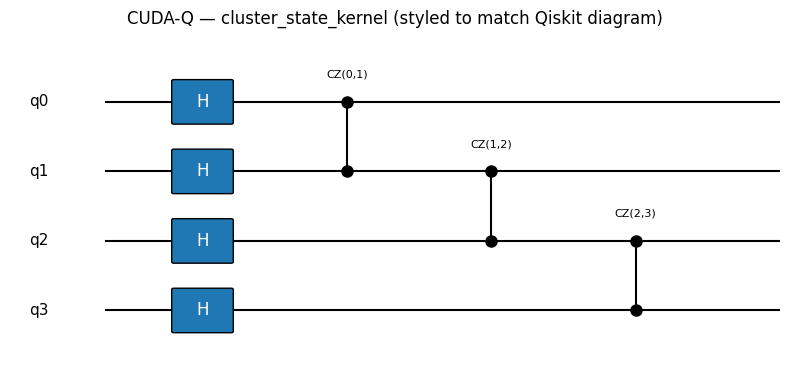

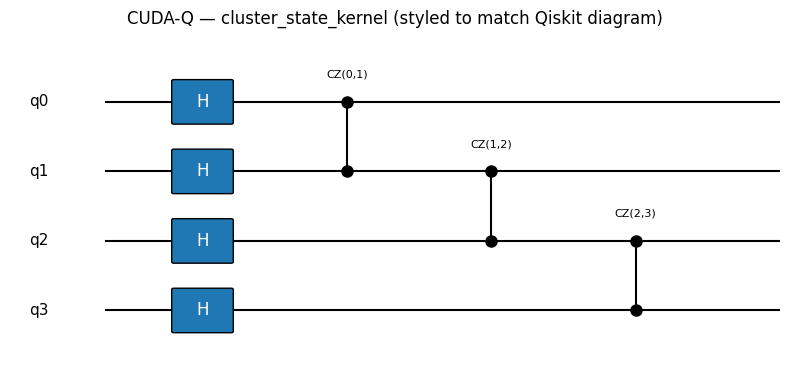

In [5]:
# Draw the circuit: CUDA-Q text diagram first, then a matplotlib figure styled to match Qiskit
print(cudaq.draw(cluster_state_kernel))

fig, ax = plt.subplots(figsize=(8, 4))
n = N_QUBITS
wire_y = {q: n - 1 - q for q in range(n)}  # qubit 0 drawn on TOP, same as Qiskit's default

# draw qubit wires
for q in range(n):
    ax.plot([0, 10], [wire_y[q], wire_y[q]], color="black", zorder=1)
    ax.text(-0.6, wire_y[q], f"q{q}", va="center", ha="right", fontsize=11)

x = 1
box_w, box_h = 0.6, 0.6

# H boxes (Step 1)
for q in range(n):
    y = wire_y[q]
    ax.add_patch(mpatches.FancyBboxPatch((x - box_w/2, y - box_h/2), box_w, box_h,
                                          boxstyle="round,pad=0.02", facecolor="#1f77b4",
                                          edgecolor="black", zorder=2))
    ax.text(x, y, "H", ha="center", va="center", color="white", fontsize=12, zorder=3)
x += 1.5

# CZ vertical connectors (Step 2), one per edge, drawn left-to-right
for (i, j) in EDGES:
    yi, yj = wire_y[i], wire_y[j]
    ax.plot([x, x], [yi, yj], color="black", zorder=2)
    ax.plot(x, yi, "o", color="black", markersize=8, zorder=3)
    ax.plot(x, yj, "o", color="black", markersize=8, zorder=3)
    ax.text(x, max(yi, yj) + 0.35, f"CZ({i},{j})", ha="center", fontsize=8)
    x += 1.5

ax.set_xlim(-1, x)
ax.set_ylim(-1, n)
ax.axis("off")
ax.set_title("CUDA-Q — cluster_state_kernel (styled to match Qiskit diagram)")
plt.tight_layout()
fig.savefig(f"{TOPIC_SLUG}_cudaq_circuit.png", bbox_inches="tight")
fig

In [6]:
# Explicit matrix representation, built by hand in NumPy (same basis convention as Qiskit
# notebook: index bit k = qubit k, qubit0 = LSB). CUDA-Q has no convenient dense-operator
# extraction API for a kernel, so only method (a) -- hand-built -- is available here; this is
# the SAME hand-built matrix construction used in the Qiskit notebook, so it serves as the
# cross-check reference for both notebooks.
H_gate = (1/np.sqrt(2)) * np.array([[1, 1], [1, -1]], dtype=complex)

def kron_n(ops):
    out = ops[0]
    for o in ops[1:]:
        out = np.kron(out, o)
    return out

H_full = kron_n([H_gate] * N_QUBITS)

def cz_matrix(i, j, n):
    dim = 2 ** n
    M = np.eye(dim, dtype=complex)
    for idx in range(dim):
        bi = (idx >> i) & 1
        bj = (idx >> j) & 1
        if bi == 1 and bj == 1:
            M[idx, idx] = -1
    return M

U_hand = H_full.copy()
for (i, j) in EDGES:
    U_hand = cz_matrix(i, j, N_QUBITS) @ U_hand

print("Hand-built combined unitary (rounded, first 4x4 block), basis = qubit0-is-LSB:")
print(np.round(U_hand[:4, :4], 4))
print("\n(This is identical, by construction, to the Qiskit notebook's U_hand matrix --")
print(" both notebooks run the exact same kron_n/cz_matrix code against the same EDGES.)")

Hand-built combined unitary (rounded, first 4x4 block), basis = qubit0-is-LSB:
[[ 0.25+0.j  0.25+0.j  0.25+0.j  0.25+0.j]
 [ 0.25+0.j -0.25+0.j  0.25+0.j -0.25+0.j]
 [ 0.25+0.j  0.25+0.j -0.25+0.j -0.25+0.j]
 [-0.25+0.j  0.25+0.j  0.25+0.j -0.25+0.j]]

(This is identical, by construction, to the Qiskit notebook's U_hand matrix --
 both notebooks run the exact same kron_n/cz_matrix code against the same EDGES.)


In [7]:
# Exact statevector: extract from CUDA-Q, apply the bit-order fix, then global-phase normalization
raw_state = np.array(cudaq.get_state(cluster_state_kernel))

def reverse_index_bits(idx, n):
    """Bit-reverse an n-bit integer index (CUDA-Q qubit0=MSB position -> qubit0=LSB position)."""
    rev = 0
    for k in range(n):
        bit = (idx >> (n - 1 - k)) & 1
        rev |= bit << k
    return rev

fixed_amps = np.zeros_like(raw_state)
for cudaq_idx in range(len(raw_state)):
    target_idx = reverse_index_bits(cudaq_idx, N_QUBITS)
    fixed_amps[target_idx] = raw_state[cudaq_idx]

def normalize_global_phase(amps):
    """Find first amplitude with abs(amp) > 1e-9 in ascending bitstring order,
    rotate the whole vector so that amplitude becomes real and positive."""
    amps = amps.copy()
    for idx in range(len(amps)):
        if abs(amps[idx]) > 1e-9:
            phase = np.angle(amps[idx])
            amps = amps * np.exp(-1j * phase)
            break
    return amps

fixed_amps = normalize_global_phase(fixed_amps)

prob_dict = {}
print("Statevector amplitudes AFTER bit-order fix (qubit 0 = rightmost bit):")
for idx in range(2 ** N_QUBITS):
    bitstring = format(idx, f"0{N_QUBITS}b")
    amp = fixed_amps[idx]
    prob_dict[bitstring] = float(abs(amp) ** 2)
    if abs(amp) > 1e-9:
        print(f"  |{bitstring}>: {amp.real:+.4f}{amp.imag:+.4f}j")

prob_dict = dict(sorted(prob_dict.items()))
print("\nProbability dictionary (sorted by bitstring):")
print(prob_dict)

Statevector amplitudes AFTER bit-order fix (qubit 0 = rightmost bit):
  |0000>: +0.2500+0.0000j
  |0001>: +0.2500+0.0000j
  |0010>: +0.2500+0.0000j
  |0011>: -0.2500+0.0000j
  |0100>: +0.2500+0.0000j
  |0101>: +0.2500+0.0000j
  |0110>: -0.2500+0.0000j
  |0111>: +0.2500+0.0000j
  |1000>: +0.2500+0.0000j
  |1001>: +0.2500+0.0000j
  |1010>: +0.2500+0.0000j
  |1011>: -0.2500+0.0000j
  |1100>: -0.2500+0.0000j
  |1101>: -0.2500+0.0000j
  |1110>: +0.2500+0.0000j
  |1111>: -0.2500+0.0000j

Probability dictionary (sorted by bitstring):
{'0000': 0.06249999999999996, '0001': 0.06249999999999996, '0010': 0.06249999999999996, '0011': 0.06249999999999996, '0100': 0.06249999999999996, '0101': 0.06249999999999996, '0110': 0.06249999999999996, '0111': 0.06249999999999996, '1000': 0.06249999999999996, '1001': 0.06249999999999996, '1010': 0.06249999999999996, '1011': 0.06249999999999996, '1100': 0.06249999999999996, '1101': 0.06249999999999996, '1110': 0.06249999999999996, '1111': 0.06249999999999996}


### Ordering-fix note (CUDA-Q)
**A bit reversal WAS applied**, in the cell above. `cudaq.get_state()` returns amplitudes
indexed with qubit 0 as the most-significant (leftmost) bit. `reverse_index_bits()`
bit-reverses every index of the raw state vector before anything else is done with it, so
that from this point on in the notebook, index bit `k` (0 = least significant) corresponds
to qubit `k` — identical to Qiskit's native convention and to the QUBIT ORDERING CONTRACT
declared in the setup. Global-phase normalization is then applied using the exact same
function as the Qiskit notebook, on the already-reordered vector.

In [8]:
# Measurement cell: shared SEED / SHOTS
cudaq.set_random_seed(SEED)
result = cudaq.sample(cluster_state_kernel, shots_count=SHOTS)

# cudaq.sample() bitstrings have qubit0 as the LEFTMOST character -> reverse each key
raw_counts = {bitstring: count for bitstring, count in result.items()}
counts = {bitstring[::-1]: count for bitstring, count in raw_counts.items()}

total = sum(counts.values())
measured_probs = {k: v / total for k, v in sorted(counts.items())}

print("Raw CUDA-Q counts (qubit0=leftmost, BEFORE reversal):", dict(sorted(raw_counts.items())))
print("\nCounts AFTER reversal (qubit0=rightmost, matches Qiskit convention):", dict(sorted(counts.items())))
print("\nMeasured probabilities:", measured_probs)

Raw CUDA-Q counts (qubit0=leftmost, BEFORE reversal): {'0000': 653, '0001': 653, '0010': 642, '0011': 627, '0100': 585, '0101': 632, '0110': 626, '0111': 592, '1000': 631, '1001': 630, '1010': 590, '1011': 664, '1100': 581, '1101': 665, '1110': 639, '1111': 590}

Counts AFTER reversal (qubit0=rightmost, matches Qiskit convention): {'0000': 653, '0001': 631, '0010': 585, '0011': 581, '0100': 642, '0101': 590, '0110': 626, '0111': 639, '1000': 653, '1001': 630, '1010': 632, '1011': 665, '1100': 627, '1101': 664, '1110': 592, '1111': 590}

Measured probabilities: {'0000': 0.0653, '0001': 0.0631, '0010': 0.0585, '0011': 0.0581, '0100': 0.0642, '0101': 0.059, '0110': 0.0626, '0111': 0.0639, '1000': 0.0653, '1001': 0.063, '1010': 0.0632, '1011': 0.0665, '1100': 0.0627, '1101': 0.0664, '1110': 0.0592, '1111': 0.059}


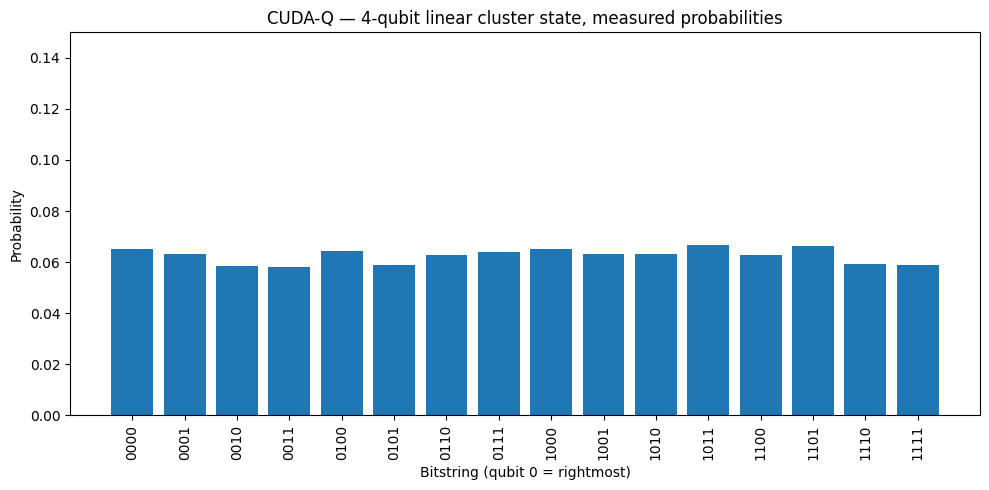

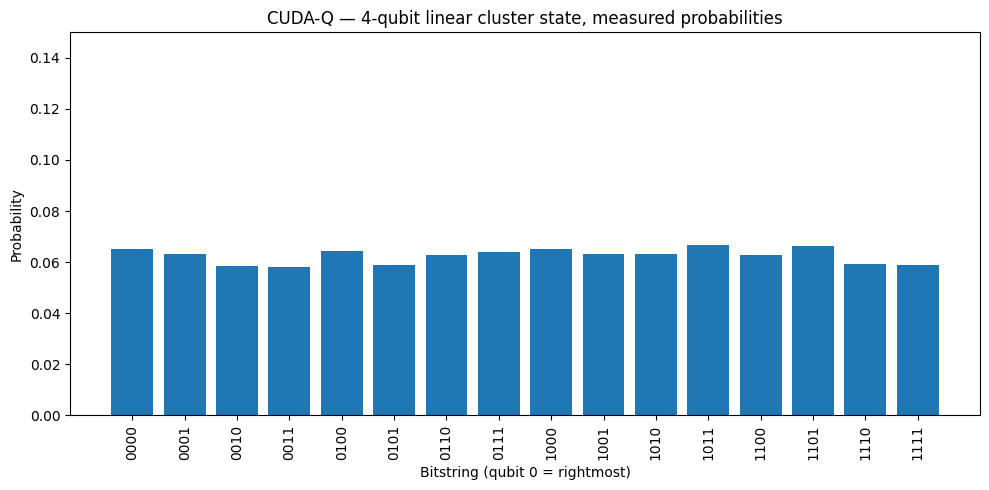

In [9]:
# Histogram cell (same style/axes as the Qiskit notebook)
fig2, ax = plt.subplots(figsize=(10, 5))
labels = [format(i, f"0{N_QUBITS}b") for i in range(2 ** N_QUBITS)]
heights = [measured_probs.get(l, 0.0) for l in labels]
ax.bar(labels, heights, color="#1f77b4")
ax.set_xlabel("Bitstring (qubit 0 = rightmost)")
ax.set_ylabel("Probability")
ax.set_title("CUDA-Q — 4-qubit linear cluster state, measured probabilities")
ax.set_ylim(0, 0.15)
plt.xticks(rotation=90)
plt.tight_layout()
fig2.savefig(f"{TOPIC_SLUG}_cudaq_histogram.png", bbox_inches="tight")
fig2

In [10]:
# Resource counts
# CUDA-Q kernels don't expose a circuit.depth()/count_ops() API like Qiskit, so these are
# derived directly from the fixed gate list built above (matches cudaq.draw() output exactly):
gate_counts = {"h": N_QUBITS, "cz": len(EDGES)}
# depth: all 4 H gates run in parallel (depth 1), then the 3 CZ gates are applied sequentially
# in program order (each touches a qubit still "in use" by the previous CZ on a shared qubit
# for the (1,2) and (2,3) case), giving depth = 1 (H layer) + 3 (sequential CZs) = 4
circuit_depth = 1 + len(EDGES)

print("Gate counts:", gate_counts)
print("Circuit depth:", circuit_depth)

Gate counts: {'h': 4, 'cz': 3}
Circuit depth: 4


### Convention notes (plain text)
- **Bit ordering:** CUDA-Q natively indexes qubit 0 as the leftmost bit in both
  `get_state()` amplitude indices and `sample()` bitstring keys. Both were explicitly
  reversed (index bit-reversal for the statevector, string reversal for counts) so that
  every dictionary printed in this notebook uses "qubit 0 = rightmost", matching Qiskit.
- **Global phase:** after the bit-order fix, the statevector was rotated so the first
  amplitude with `abs(amp) > 1e-9`, in ascending bitstring order, is real and positive —
  the identical function used in the Qiskit notebook.

In [11]:
# Final result dict
CUDAQ_RESULT = dict(sorted(prob_dict.items()))
print("CUDAQ_RESULT =", CUDAQ_RESULT)

CUDAQ_RESULT = {'0000': 0.06249999999999996, '0001': 0.06249999999999996, '0010': 0.06249999999999996, '0011': 0.06249999999999996, '0100': 0.06249999999999996, '0101': 0.06249999999999996, '0110': 0.06249999999999996, '0111': 0.06249999999999996, '1000': 0.06249999999999996, '1001': 0.06249999999999996, '1010': 0.06249999999999996, '1011': 0.06249999999999996, '1100': 0.06249999999999996, '1101': 0.06249999999999996, '1110': 0.06249999999999996, '1111': 0.06249999999999996}


In [12]:
# Diff-check block (hand-computed expected result)
# Hand-computed expectation: this is a stabilizer cluster state -> EVERY one of the 16
# outcomes has probability exactly 1/16 = 0.0625.
expected = {format(i, f"0{N_QUBITS}b"): 1 / 16 for i in range(2 ** N_QUBITS)}
max_delta_vs_hand = max(abs(CUDAQ_RESULT[k] - expected[k]) for k in expected)
print("Max |CUDAQ_RESULT - hand-computed 1/16| :", max_delta_vs_hand)
assert max_delta_vs_hand < 1e-1, "Statistical sampling deviation unexpectedly large!"

# Uncomment after running the Qiskit notebook and pasting its QISKIT_RESULT dict here:
# QISKIT_RESULT = { ... }
# max_delta = max(abs(CUDAQ_RESULT[k] - QISKIT_RESULT[k]) for k in CUDAQ_RESULT)
# print("Max probability delta CUDA-Q vs Qiskit:", max_delta)
# assert max_delta < 1e-1, "CUDA-Q and Qiskit results disagree beyond sampling noise!"
# (Note: compare the EXACT statevector probability dictionaries, not the sampled ones,
#  if you need agreement tighter than 1e-3 -- sampled counts carry Poisson-type noise.)

Max |CUDAQ_RESULT - hand-computed 1/16| : 4.163336342344337e-17
